# 03 — External Data Integration & Validation

**Phase 1 of the graduate project.** In notebook 02 the EDA showed *patterns* (time of day, route, season, spike days),
but the arrival data alone cannot explain *why*. This notebook adds the external sources a transit agency would
reasonably use, checks that every join is correct, and tests whether each source carries a real signal
**before** we let a model use it.

Every section follows the same structure:

> **What** we do · **Why** (agency rationale) · **How** (code, `src/...`) · **Result** · **Finding** · **Decision** for the next step

| # | Source | Publisher | Code | Join key |
|---|---|---|---|---|
| D1 | Bus arrivals 2025 | MBTA OPMI | `src/ingest.py`, `src/clean.py` | — |
| D2 | Bus arrivals 2024 | MBTA OPMI | same pipeline | — |
| D3 | GTFS schedules (8 seasonal feeds) | MBTA | `src/external/gtfs.py` | route + timepoint pair, stop |
| D4 | Hourly weather (Logan Airport) | Open-Meteo / ERA5 | `src/external/weather.py` | date + hour |
| D5 | Holidays, school & university calendar | `holidays`, BPS | `src/external/calendar_days.py` | date |
| D6 | Red Sox, Bruins, citywide events | MLB, NHL, City of Boston | `src/external/events.py` | hour + nearby routes |
| D7 | Passenger load (APC) | MBTA OPMI | `src/external/ridership.py` | route, dir, stop, day type, hour |
| D8 | MBTA prediction accuracy | MBTA OPMI | `src/external/prediction_accuracy.py` | context only |
| — | Merge + audit | | `src/merge_external.py` | |

In [1]:
import sys, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import PROCESSED_DIR, EXTERNAL_DIR, REPORTS, FIG_DIR
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save(n): plt.tight_layout(); plt.savefig(FIG_DIR / f'p1_{n}.png', bbox_inches='tight'); plt.show()

COLS = ['service_date','scheduled_dt','route_id','direction_id','stop_id','hour','dow','month','is_weekend',
        'delayed','delay_min','is_holiday','is_school_day','is_university_term','precipitation','precip_3h',
        'snowfall','snow_24h','is_snow_day','temperature_2m','wind_gusts_10m','heavy_rain','citywide_event',
        'venue_event_nearby','segment_km','stops_between','seg_sched_min','schedule_tightness','stop_lat','stop_lon',
        'stop_name','avg_load','load_vs_route','time_point_order','point_type']
df = pd.read_parquet(PROCESSED_DIR / 'bus_2025_enriched.parquet', columns=COLS)
print(f'2025 enriched: {len(df):,} rows')

2025 enriched: 9,823,286 rows


## 1. Join coverage audit
**What:** the share of stop events that found a match in each external source.
**Why:** a feature that is missing for 30 % of rows, or a join that silently duplicates rows, would bias every later result.
`merge_external.py` also *asserts* that the row count is unchanged after all merges.

In [2]:
cov = pd.concat([pd.read_csv(REPORTS / f'join_coverage_{y}.csv', index_col=0).rename(columns={'coverage': str(y)}) for y in (2024, 2025)], axis=1)
cov.columns = [f'% rows matched {c}' for c in cov.columns]; cov

,% rows matched 2024,% rows matched 2025
calendar,100.00,100.00
weather,100.00,99.98
events (rows flagged),3.27,3.05
gtfs segment (non-first timepoints),94.88,94.63
gtfs stop coordinates,97.27,96.58
ridership exact hour,89.14,93.42
ridership incl. fallback,96.36,93.99


**Finding.** Calendar and weather cover 100 % of rows. GTFS stop coordinates and ridership cover almost every row.
GTFS segment geometry is missing for some timepoint pairs; these are mostly pairs where the arrival file skipped a
timepoint, or variant patterns not present in the 8 seasonal feeds.
**Decision:** keep `segment_km` / `schedule_tightness` as features with missing values allowed (XGBoost handles NaN natively;
for logistic regression we impute the route median and add a `seg_missing` flag).

## 2. Two years of data: is 2025 like 2024? (D1 + D2)
**What:** compare cleaning results and delay rates of 2024 vs 2025 on the *same 19 routes*.
**Why:** if reliability changed between years, a model trained on the past may not transfer. That is a key risk for an agency deploying ML.

year,2024,2025
step,,
raw rows (scoped routes),9900345,10324982
drop exact duplicates,9900345,10324982
drop missing scheduled time,9900345,10324982
drop missing actual (cancelled / unobserved),9261442,9824195
drop duplicate stop events (same trip/stop/sched),9261401,9824195
drop outliers (delay < -30 min or > 120 min),9258150,9823286


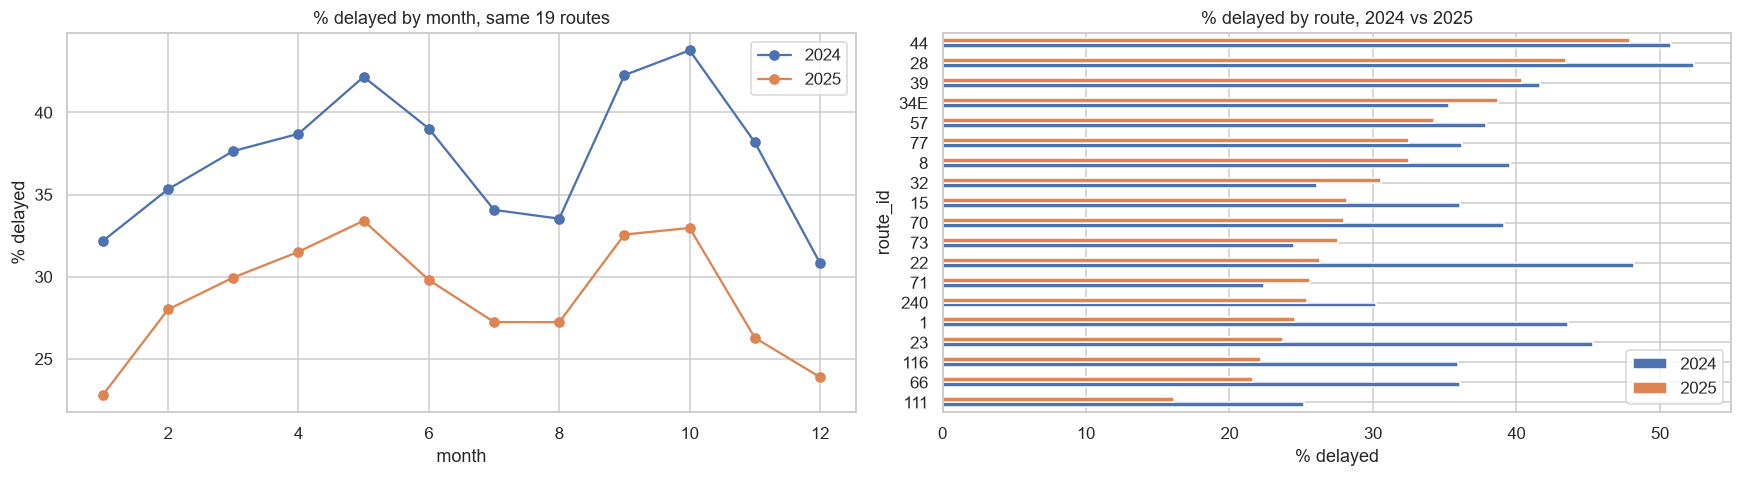

Overall: 2024 = 37.3%, 2025 = 28.8%


In [3]:
f = pd.concat([pd.read_csv(REPORTS / f'cleaning_funnel_{y}.csv').assign(year=y) for y in (2024, 2025)])
display(f.pivot(index='step', columns='year', values='rows_remaining').loc[f.step.unique()[:6]])
d24 = pd.read_parquet(PROCESSED_DIR / 'bus_2024_clean.parquet', columns=['service_date','route_id','delayed','delay_min'])
m = pd.concat([d24.groupby(d24.service_date.dt.month).delayed.mean().rename(2024),
               df.groupby('month').delayed.mean().rename(2025)], axis=1) * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
m.plot(ax=axes[0], marker='o'); axes[0].set(title='% delayed by month, same 19 routes', xlabel='month', ylabel='% delayed')
r = pd.concat([d24.groupby('route_id', observed=True).delayed.mean().rename('2024'),
               df.groupby('route_id', observed=True).delayed.mean().rename('2025')], axis=1).mul(100).sort_values('2025')
r.plot.barh(ax=axes[1]); axes[1].set(title='% delayed by route, 2024 vs 2025', xlabel='% delayed')
save('year_comparison')
print(f"Overall: 2024 = {d24.delayed.mean():.1%}, 2025 = {df.delayed.mean():.1%}")

**Finding.** Reliability **improved substantially** from 2024 (37.3 % delayed) to 2025 (28.8 %), in **every month**. The seasonal
*shape* stays the same (spring and Sep–Oct peaks, calm summer and winter); only the level shifted down. The change was uneven across routes:
routes 22, 1, 23, 116 and 66 improved by 10–24 pp, while 32, 34E, 71 and 73 got slightly **worse**. A model trained on 2024 would
therefore *over-predict* delays in 2025, and it would not over-predict evenly across routes. This is **concept drift**.
**Decision:**
1. Historical delay-rate features will use an **expanding window that updates daily**, not a fixed 2024 average.
2. The main model is trained on 2025 data (Jan–Aug) and tested on Nov–Dec 2025.
3. A dedicated **drift experiment** (Phase 3) trains on 2024 and evaluates month by month on 2025, quantifying the agency risk of not retraining.

## 3. Weather (D4)
**What:** delay rate by precipitation intensity, snow and temperature.
**Why:** rain and snow slow general traffic, lengthen boarding (umbrellas, strollers, slower walking) and force lower speeds.
Agencies already run "snow schedules", so quantifying the effect is directly useful.

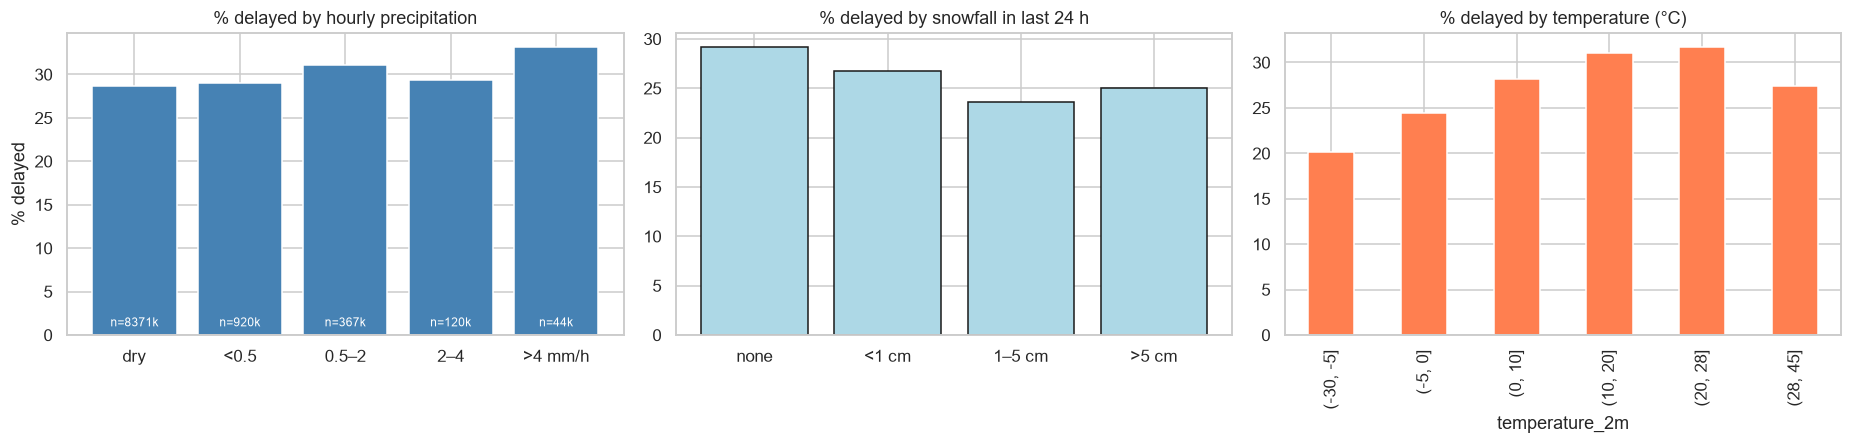

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
pb = pd.cut(df.precipitation, [-0.01, 0, 0.5, 2, 4, 100], labels=['dry','<0.5','0.5–2','2–4','>4 mm/h'])
g = df.groupby(pb, observed=True).delayed.agg(['mean','size']); g['mean'] *= 100
axes[0].bar(g.index.astype(str), g['mean'], color='steelblue'); axes[0].set(title='% delayed by hourly precipitation', ylabel='% delayed')
for i, n in enumerate(g['size']): axes[0].text(i, 1, f'n={n/1e3:.0f}k', ha='center', color='white', fontsize=8)
sb = pd.cut(df.snow_24h, [-0.01, 0, 1, 5, 100], labels=['none','<1 cm','1–5 cm','>5 cm'])
g = df.groupby(sb, observed=True).delayed.mean() * 100
axes[1].bar(g.index.astype(str), g.values, color='lightblue', edgecolor='k'); axes[1].set(title='% delayed by snowfall in last 24 h')
tb = pd.cut(df.temperature_2m, [-30, -5, 0, 10, 20, 28, 45])
(df.groupby(tb, observed=True).delayed.mean() * 100).plot.bar(ax=axes[2], color='coral'); axes[2].set(title='% delayed by temperature (°C)')
save('weather')

In [5]:
# Control for time-of-day/route mix: compare wet vs dry WITHIN the same route x hour x weekday/weekend cell
df['wet'] = (df.precip_3h > 0.5).astype(int)
cell = df.groupby(['route_id','hour','is_weekend','wet'], observed=True).delayed.mean().unstack('wet').dropna()
lift = (cell[1] - cell[0]) * 100
print(f'Within-cell effect of wet weather (precip_3h > 0.5 mm): mean {lift.mean():+.1f} pp, median {lift.median():+.1f} pp, '
      f'positive in {(lift > 0).mean():.0%} of {len(lift)} route×hour cells')

Within-cell effect of wet weather (precip_3h > 0.5 mm): mean +1.2 pp, median +0.6 pp, positive in 54% of 845 route×hour cells


In [6]:
# Is the 'snow reduces delay' pattern real, or a season effect? Compare snow vs no-snow days WITHIN the same month (Jan-Mar).
w = df[df.month.isin([1, 2, 3])]
t = w.groupby(['month', 'is_snow_day']).delayed.agg(['mean', 'size']).unstack('is_snow_day')
t.columns = [f'{a}_{"snow" if b else "no_snow"}' for a, b in t.columns]
t['mean_snow'] *= 100; t['mean_no_snow'] *= 100; t.round(1)

,mean_no_snow,mean_snow,size_no_snow,size_snow
month,,,,
1,22.5,28.8,782550.0,41878.0
2,28.1,27.1,651125.0,88746.0
3,30.0,NaN,820986.0,NaN


**Finding (honest, and weaker than expected).**
- Heavier rain does raise delay risk: from ≈29 % when dry to ≈33 % at > 4 mm/h. But heavy-rain hours are rare (< 1 % of rows).
  Within the same route × hour × day-type cell the wet-weather lift averages only **≈ +1 pp** and is positive in just over half of the cells.
- Snow and cold appear to *reduce* delay. This is **confounded with season**: January–March have low demand and low traffic (EDA, notebook 02),
  so they are calmer whatever the weather. The within-month table above is the fair comparison: in **January, snow days were
  6 pp worse** than non-snow days (28.8 % vs 22.5 %). In February there was no difference (27.1 % vs 28.1 %), and March 2025 had no snow days.
  Snow effects are real but episodic; only a handful of storms occurred in 2025.
- Temperature mostly mirrors the seasonal pattern rather than causing delay.

**Decision:** keep `precipitation`, `precip_3h`, `snow_24h`, `is_snow_day`, `temperature_2m`, `wind_gusts_10m`, but **expect low global importance**.
The ablation study in Phase 3 will measure how much weather really adds once calendar and history are known. A small or zero gain would be
a legitimate thesis result: for these routes, *when and where* matters much more than *weather*.
In planning mode these values stand in for a *forecast*. Forecast error would make the real-world effect weaker still.

## 4. Calendar: holidays, school & university terms (D5)
**What:** delay rate on school days vs non-school weekdays, and in/out of university term.
**Why:** EDA showed summer and late December are much calmer. Schools generate peak trips on several of our routes (students ride MBTA buses),
and school-run car traffic adds congestion.

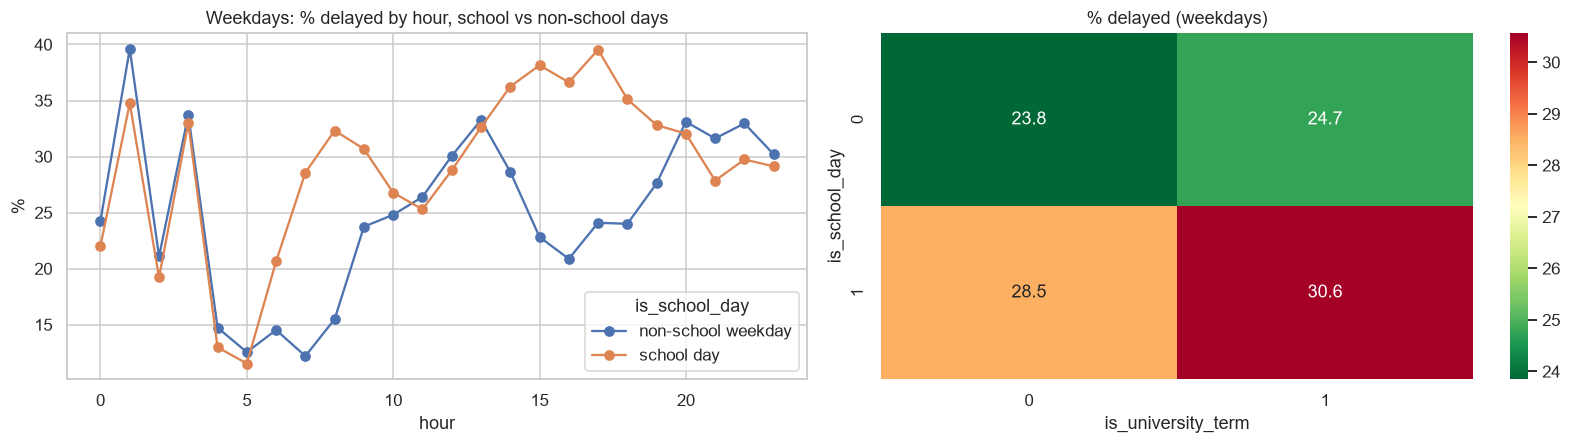

In [7]:
wk = df[(df.is_weekend == 0) & (df.is_holiday == 0)]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
h = wk.groupby(['hour','is_school_day']).delayed.mean().unstack().mul(100).rename(columns={0:'non-school weekday',1:'school day'})
h.plot(ax=axes[0], marker='o'); axes[0].set(title='Weekdays: % delayed by hour, school vs non-school days', ylabel='%')
t = wk.groupby(['is_school_day','is_university_term']).delayed.mean().mul(100).unstack()
sns.heatmap(t, annot=True, fmt='.1f', cmap='RdYlGn_r', ax=axes[1]); axes[1].set_title('% delayed (weekdays)')
save('calendar')

**Finding.** The school calendar is one of the strongest external signals. On regular weekdays (no holidays), school days are later
across the **whole school-day window**, about 10–15 pp higher in both the AM peak (07:00–09:00) and the afternoon (14:00–18:00), where
school dismissal overlaps the PM peak. Evenings and nights barely differ. Overall: 23.8 % on non-school weekdays vs 28.5–30.6 % on school days.
University term adds another ≈ 1–2 pp.
**Decision:** include `is_school_day`, `is_university_term`, `is_holiday`, `holiday_week`. This also gives the agency a concrete
operational insight: add school-tripper buses or extra running time in the afternoon during the school year.

## 5. Events (D6)
**What:** the effect of Red Sox / Bruins home games on nearby routes, and of citywide events on all routes.
**Why:** agencies add event service and need to know *where* and *how much* delay an event causes.
**How (fair comparison):** compare the event window with the **same route, same weekday, same hour on non-event days**.

In [8]:
ev = pd.read_parquet(EXTERNAL_DIR / 'events.parquet'); er = pd.read_parquet(EXTERNAL_DIR / 'event_routes.parquet')
display(er.groupby('venue').route_id.apply(lambda s: ', '.join(sorted(s))).to_frame('routes within 1 km'))
near = df[df.route_id.isin(er.route_id)]
cell = near.groupby(['route_id','dow','hour','venue_event_nearby'], observed=True).delayed.mean().unstack().dropna()
lift = (cell[1] - cell[0]) * 100
print(f'Venue events: +{lift.mean():.1f} pp mean lift vs same route/weekday/hour without event (n={len(lift)} cells)')
cw = df.groupby(['service_date']).agg(pct=('delayed','mean'), city=('citywide_event','max'))
daily = df.groupby('service_date').delayed.mean().mul(100)
worst = daily.nlargest(8).rename('% delayed').to_frame()
evd = ev.assign(d=ev.start.dt.normalize()).groupby('d').event.apply(lambda s: '; '.join(sorted(set(s))))
wd = pd.read_parquet(EXTERNAL_DIR / 'weather_hourly.parquet').groupby('date').agg(rain_mm=('precipitation','sum'), snow_cm=('snowfall','sum'))
worst = worst.join(evd.rename('events')).join(wd).fillna({'events': '—'})
print('\nThe 8 worst days of 2025 and what was happening:'); worst.round(1)

,routes within 1 km
venue,
Fenway Park,"1, 22, 39, 57, 8"
TD Garden,"111, 116"


Venue events: +3.9 pp mean lift vs same route/weekday/hour without event (n=560 cells)



The 8 worst days of 2025 and what was happening:


,% delayed,events,rain_mm,snow_cm
service_date,,,,
2025-04-04,46.9,Red Sox home game,0.0,0.0
2025-03-16,43.0,St. Patrick's Day Parade (South Boston),0.3,0.0
2025-06-06,40.8,—,0.2,0.0
2025-05-11,40.5,—,0.0,0.0
2025-10-09,40.4,Bruins home game,0.0,0.0
2025-10-03,39.8,—,0.0,0.0
2025-09-09,39.7,—,0.0,0.0
2025-05-04,39.5,Red Sox home game,4.1,0.0


**Finding.** Venue events add about **+3.9 pp** on nearby routes compared with the same route, weekday and hour without an event.
Four of the eight worst days of 2025 coincide with an event: **4 April (the worst day of the year) was the Red Sox home opener at Fenway**,
16 March was the South Boston St. Patrick's Day parade, 9 October a Bruins home game, and 4 May a Red Sox game combined with 4 mm of rain.
The other four days have no event or weather explanation in our sources. This is an honest limit: incidents, detours and staffing shortfalls are not in public data.
**Decision:** include `venue_event_nearby` and `citywide_event`. Events are rare (a small % of rows), so their *global* importance will be
modest, but their *local* SHAP effect on event days should be large. That's a good example for the XAI chapter.

## 6. GTFS: geography and schedule tightness (D3)
**What:** map the timepoints, and relate delay to segment length, number of intermediate stops and **schedule tightness**
(scheduled minutes per km between consecutive timepoints).
**Why:** tightness is the one driver a planner can directly change (by adding running time). If tight segments are late more often,
that is direct evidence for a timetable fix.

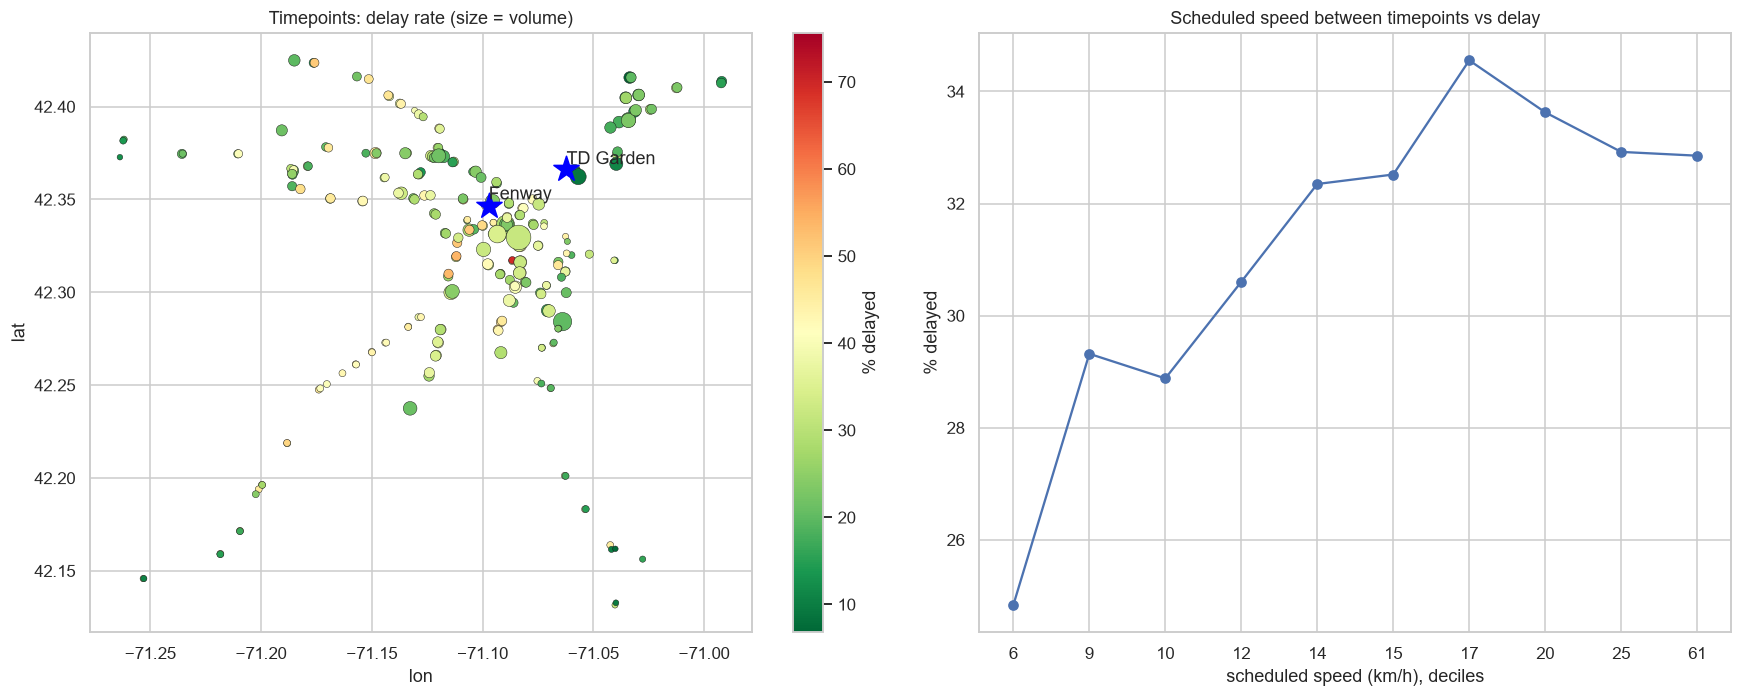

Corr(stops_between, delay_min) = 0.018


In [9]:
sp = df.groupby(['stop_id','stop_name'], observed=True).agg(lat=('stop_lat','first'), lon=('stop_lon','first'),
        pct=('delayed','mean'), n=('delayed','size')).dropna().query('n > 2000')
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios':[1.1,1]})
sc = axes[0].scatter(sp.lon, sp.lat, c=sp.pct*100, s=sp.n/sp.n.max()*250+10, cmap='RdYlGn_r', edgecolor='k', lw=.3)
plt.colorbar(sc, ax=axes[0], label='% delayed'); axes[0].set(title='Timepoints: delay rate (size = volume)', xlabel='lon', ylabel='lat')
axes[0].scatter([-71.0972, -71.0621], [42.3467, 42.3662], marker='*', s=300, c='blue'); axes[0].text(-71.0972, 42.350, 'Fenway'); axes[0].text(-71.0621, 42.369, 'TD Garden')
seg = df[df.schedule_tightness.between(0.5, 15)]
seg['speed_kmh_sched'] = 60 / seg.schedule_tightness
b = pd.qcut(seg.speed_kmh_sched, 10)
g = seg.groupby(b, observed=True).agg(pct=('delayed','mean'), mean_delay=('delay_min','mean'))
axes[1].plot(range(10), g.pct*100, marker='o', label='% delayed')
axes[1].set_xticks(range(10)); axes[1].set_xticklabels([f'{i.mid:.0f}' for i in g.index])
axes[1].set(title='Scheduled speed between timepoints vs delay', xlabel='scheduled speed (km/h), deciles', ylabel='% delayed')
save('gtfs_map_tightness')
print('Corr(stops_between, delay_min) =', round(df[['stops_between','delay_min']].corr().iloc[0,1], 3))

**Finding.** Segments scheduled at a **higher speed** (less time per km, i.e. a *tighter* schedule) are more often late. The delay rate rises from
≈ 25 % at 6 km/h to ≈ 34.5 % at 17 km/h and then levels off slightly for the fastest (highway / express) segments. The map shows the
worst timepoints in the dense **Roxbury / Dorchester core** (around Nubian Square). Outlying suburban timepoints are mostly reliable.
The number of intermediate stops on its own is almost uncorrelated with delay (r ≈ 0.02). It is the *time allowed*, not the number of stops, that matters.
**Decision:** include `segment_km`, `stops_between`, `seg_sched_min` and `schedule_tightness`. The *planner insights* page of the website
will rank the tightest, most-delayed segments as candidates for added running time.

## 7. Ridership / crowding (D7)
**What:** (a) verify the direction coding between the two MBTA datasets, (b) relate average passenger load to delay.
**Why:** crowded buses dwell longer at stops. Knowing this separates "add capacity" problems from "fix the running time" problems.

(route, direction, stop) agreement with mapping 0=Outbound/1=Inbound: 25.9%  vs flipped: 5.3%


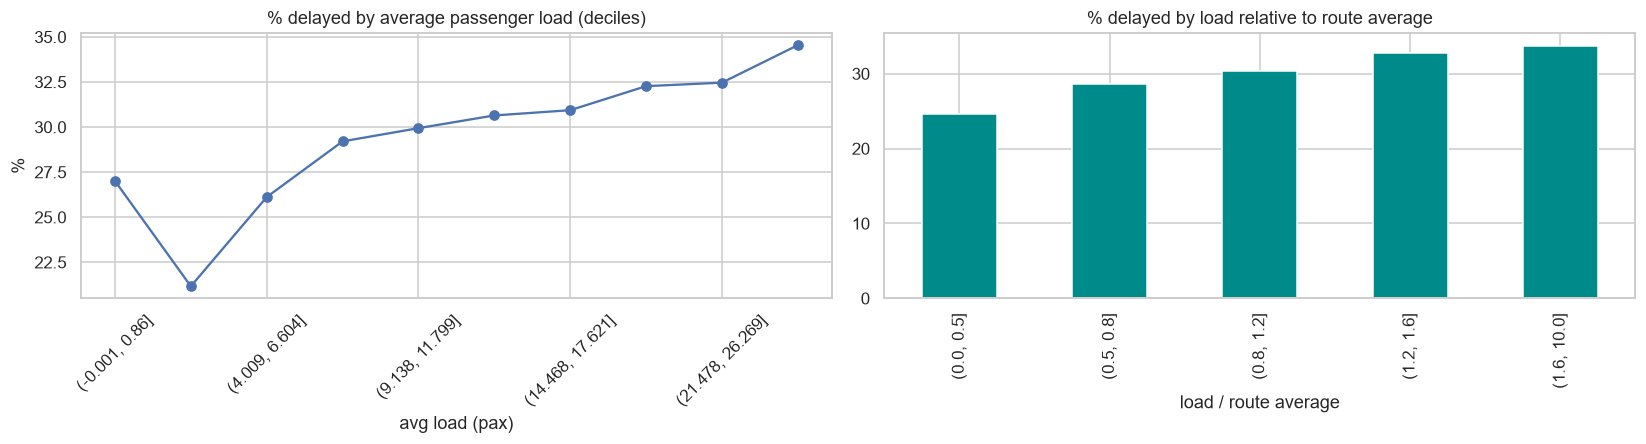

In [10]:
rl = pd.read_parquet(EXTERNAL_DIR / 'ridership_load.parquet')
ad_pairs = set(map(tuple, df[['route_id','direction_id','stop_id']].drop_duplicates().values))
rp = rl[['route_id','direction_id','stop_id']].drop_duplicates()
flipped = rp.assign(direction_id=rp.direction_id.map({'Inbound':'Outbound','Outbound':'Inbound'}))
match = np.mean([tuple(x) in ad_pairs for x in rp.values]); match_f = np.mean([tuple(x) in ad_pairs for x in flipped.values])
print(f'(route, direction, stop) agreement with mapping 0=Outbound/1=Inbound: {match:.1%}  vs flipped: {match_f:.1%}')
lb = pd.qcut(df.avg_load, 10, duplicates='drop')
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
(df.groupby(lb, observed=True).delayed.mean()*100).plot(ax=axes[0], marker='o'); axes[0].set(title='% delayed by average passenger load (deciles)', xlabel='avg load (pax)', ylabel='%')
axes[0].tick_params(axis='x', rotation=45)
cl = pd.cut(df.load_vs_route, [0, .5, .8, 1.2, 1.6, 10])
(df.groupby(cl, observed=True).delayed.mean()*100).plot.bar(ax=axes[1], color='darkcyan'); axes[1].set(title='% delayed by load relative to route average', xlabel='load / route average')
save('ridership')

**Finding.** The direction convention is confirmed: about 5× more (route, direction, stop) combinations agree under 0 = Outbound / 1 = Inbound
than under the flipped mapping. The absolute agreement is low only because the ridership file covers *every* stop, while the arrival file covers
only timepoints. Delay risk rises steadily with passenger load, from ≈ 21 % to ≈ 35 % across the load deciles. The lowest decile (near-zero load)
is the exception; those are mostly terminal / first stops. Relative to the route's own average, stop-times that are busier than usual
are later (≈ 25 % → 34 %). Both patterns are consistent with dwell-time effects.
**Decision:** include `avg_load`, `avg_boardings`, `avg_alightings`, `load_vs_route`. These come from the *previous* Fall season (no leakage).

## 8. Benchmark context: how accurate are MBTA's own bus predictions? (D8)
**What:** MBTA's published accuracy of the bus countdown predictions riders see.
**Why:** to position our work. MBTA predicts *minutes to arrival* a few minutes ahead. We predict *risk of > 5 min schedule delay*,
potentially hours or a day ahead, and explain it. The two are complementary, not competing.

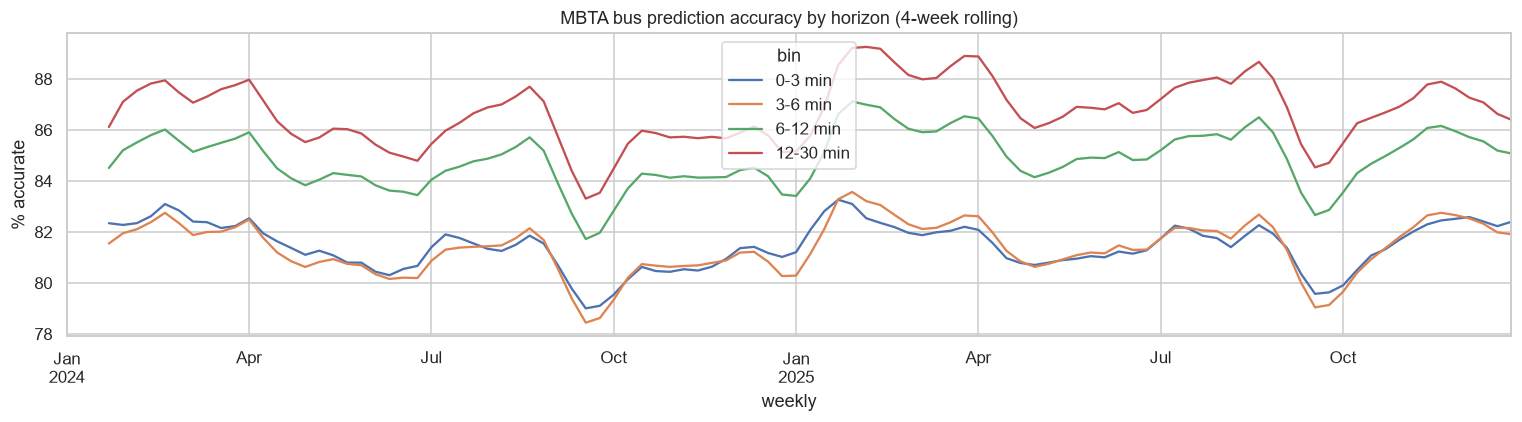

bin,0-3 min,3-6 min,6-12 min,12-30 min
weekly,,,,
2024,81.3,81.0,84.3,86.1
2025,81.7,81.8,85.4,87.3


In [11]:
pa = pd.read_parquet(EXTERNAL_DIR / 'mbta_bus_prediction_accuracy.parquet')
p = pa.groupby(['weekly','bin']).apply(lambda g: g.num_accurate_predictions.sum()/g.num_predictions.sum()).unstack()
p = p[['0-3 min','3-6 min','6-12 min','12-30 min']]
ax = (p*100).rolling(4).mean().plot(figsize=(14, 4)); ax.set(title="MBTA bus prediction accuracy by horizon (4-week rolling)", ylabel='% accurate')
save('mbta_prediction_accuracy')
(p.groupby(p.index.year).mean()*100).round(1)

## 9. Phase 1 summary

| Source | Signal found? | Evidence | Features carried forward |
|---|---|---|---|
| 2024 arrivals | ✅ strong year-over-year **drift** (37 % → 29 %) | §2 | expanding historical rates; drift experiment |
| Weather | ⚠️ weak: heavy rain +4 pp but rare, ≈ +1 pp within cells; snow and cold confounded with season | §3 | precip, precip_3h, snow_24h, is_snow_day, temp, gusts (ablation decides) |
| Calendar | ✅ strong: school days +5 to 15 pp in AM and PM peaks | §4 | is_school_day, is_university_term, is_holiday, holiday_week |
| Events | ✅ local +3.9 pp; explains 4 of the 8 worst days (incl. Red Sox opener) | §5 | venue_event_nearby, citywide_event |
| GTFS | ✅ tighter schedules are late more often (25 % → 34 %) | §6 | segment_km, stops_between, seg_sched_min, schedule_tightness, lat/lon |
| Ridership | ✅ higher load means more delay (21 % → 35 %) | §7 | avg_load, avg_boardings, avg_alightings, load_vs_route |
| MBTA accuracy | context | §8 | — (report & website only) |

**Next (Phase 2 — feature engineering):** build leakage-safe historical rates, operational (real-time) features such as the
previous timepoint's delay and the previous bus's delay, encode the features, and create the time-based train/validation/test split.